EoS force 1000


/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Mounted at /content/drive
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)



Loading initial structure from validation set...

--- PHASE 1: Relaxing to 0K Equilibrium ---
       Step     Time          Energy          fmax
LBFGS:    0 11:09:54     -479.322906        1.014834
LBFGS:    1 11:09:54     -479.505035        0.890491
LBFGS:    2 11:09:55     -479.884827        1.109490
LBFGS:    3 11:09:56     -480.308716        1.709028
LBFGS:    4 11:09:57     -480.655945        1.132620
LBFGS:    5 11:09:57     -480.851257        0.575070
LBFGS:    6 11:09:57     -480.999268        0.590534
LBFGS:    7 11:09:57     -481.125824        0.781901
LBFGS:    8 11:09:57     -481.238281        0.591279
LBFGS:    9 11:09:57     -481.326904        0.558585
LBFGS:   10 11:09:58     -481.405029        0.395454
LBFGS:   11 11:09:58     -481.487274        0.569777
LBFGS:   12 11:09:58     -481.572327        0.505201
LBFGS:   13 11:09:58     -481.647827        0.426756
LBFGS:   14 11:09:58     -481.716949        0.378758
LBFGS:   15 11:09:58     -481.793152        0.451311
LBFGS:

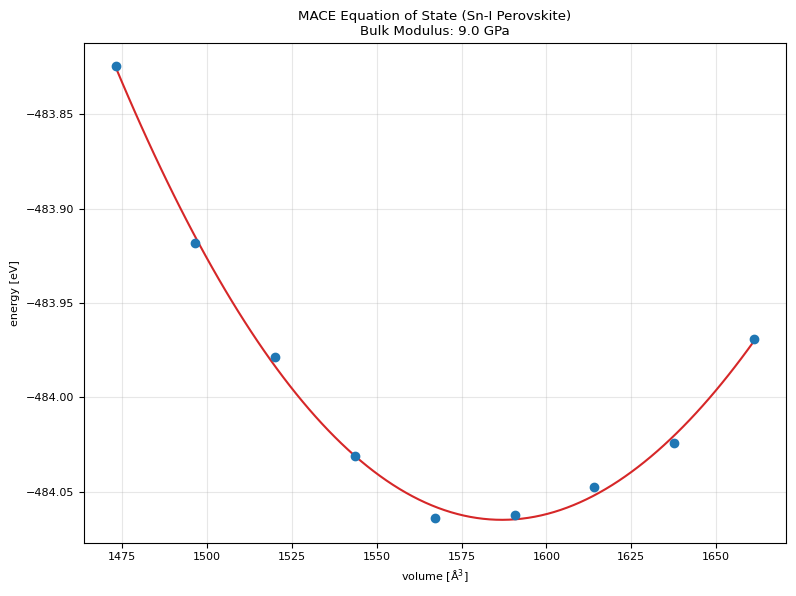

Analysis complete! Plot saved to /content/mace_equation_of_state.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from ase.optimize import LBFGS
from ase.filters import FrechetCellFilter
from ase.eos import EquationOfState
from mace.calculators import MACECalculator
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# File Paths
base_dir = '/content/drive/MyDrive/MDProject'
init_structure_path = os.path.join(base_dir, 'valid.extxyz')
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/force1000/model_3000_pts_force1000_run-1_stagetwo.model"

# Load the MACE Model
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

# Load and Prepare the Initial Structure
print("\nLoading initial structure from validation set...")
atoms = read(init_structure_path, index=0)
atoms.calc = calc

# FIND THE 0K EQUILIBRIUM
# FrechetCellFilter allows the optimizer to relax atomic positions and the box dimensions
ucf = FrechetCellFilter(atoms)
opt = LBFGS(ucf, trajectory=os.path.join(base_dir, 'relaxation.traj'))
# We stop when the maximum force on any atom drops below 0.05 eV/A
opt.run(fmax=0.05, steps=200)

opt_cell = atoms.get_cell()
opt_vol = atoms.get_volume()
print(f"Optimized Equilibrium Volume: {opt_vol:.2f} A^3")

# APPLY MACROSCOPIC STRAIN
# We will scale the volume from -6% to +6% of the volume
scale_factors = np.linspace(0.94, 1.06, 9)

volumes = []
energies = []

for scale in scale_factors:
    atoms_strained = atoms.copy()
    atoms_strained.calc = calc

    # Scale the cell
    linear_scale = scale ** (1.0 / 3.0)
    atoms_strained.set_cell(opt_cell * linear_scale, scale_atoms=True)

    #Let the internal atomic coordinates relax
    opt_internal = LBFGS(atoms_strained, logfile=None) # Mute output for clean logs
    opt_internal.run(fmax=0.05, steps=50)

    # Record the volume and potential energy
    v = atoms_strained.get_volume()
    e = atoms_strained.get_potential_energy()

    volumes.append(v)
    energies.append(e)

    print(f"Volume Scale: {scale*100:>5.1f}% | Absolute Vol: {v:>8.2f} A^3 | Energy: {e:>10.3f} eV")

# FIT TO BIRCH-MURNAGHAN EOS
eos = EquationOfState(volumes, energies, eos='birchmurnaghan')
v0, e0, B = eos.fit()

# Convert Bulk Modulus (B) from eV/A^3 to GPa
B_GPa = B * 160.217662


print(f"Equilibrium Energy (E0): {e0:.3f} eV")
print(f"Equilibrium Volume (V0): {v0:.2f} A^3")
print(f"Bulk Modulus (B):        {B_GPa:.2f} GPa")

# PLOT
# Use ASE's native plotting tool to handle the fit curve automatically
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)
eos.plot(ax=ax)

# Override the default title to include your MACE Bulk Modulus
plt.title(f'MACE Equation of State (Sn-I Perovskite)\nBulk Modulus: {B_GPa:.1f} GPa')
plt.grid(True, alpha=0.3)
plt.tight_layout()

save_path = '/content/mace_equation_of_state.png'
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Analysis complete! Plot saved to {save_path}")

EoS force 10

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)



Loading initial structure from validation set...

--- PHASE 1: Relaxing to 0K Equilibrium ---
       Step     Time          Energy          fmax
LBFGS:    0 11:10:25     -479.322784        1.006558
LBFGS:    1 11:10:26     -479.504425        0.925987
LBFGS:    2 11:10:26     -479.882690        1.085041
LBFGS:    3 11:10:26     -480.299347        1.677340
LBFGS:    4 11:10:26     -480.644226        1.114093
LBFGS:    5 11:10:26     -480.839905        0.596881
LBFGS:    6 11:10:26     -480.989380        0.621677
LBFGS:    7 11:10:26     -481.119232        0.755519
LBFGS:    8 11:10:26     -481.234039        0.614305
LBFGS:    9 11:10:26     -481.328125        0.587491
LBFGS:   10 11:10:26     -481.411224        0.407909
LBFGS:   11 11:10:26     -481.495544        0.542794
LBFGS:   12 11:10:26     -481.579254        0.475361
LBFGS:   13 11:10:26     -481.651245        0.433266
LBFGS:   14 11:10:26     -481.716034        0.375545
LBFGS:   15 11:10:27     -481.785156        0.405984
LBFGS:

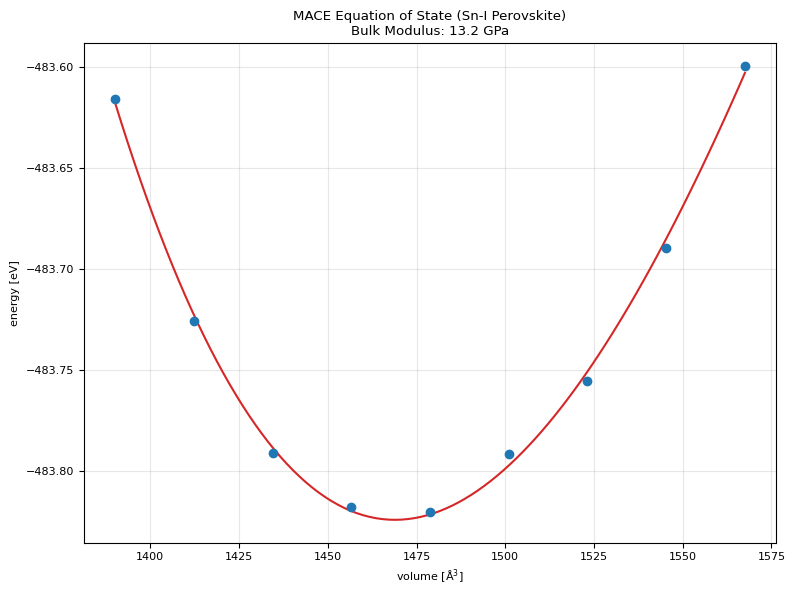

Analysis complete! Plot saved to /content/mace_equation_of_state.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from ase.optimize import LBFGS
from ase.filters import FrechetCellFilter
from ase.eos import EquationOfState
from mace.calculators import MACECalculator
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# File Paths
base_dir = '/content/drive/MyDrive/MDProject'
init_structure_path = os.path.join(base_dir, 'valid.extxyz')
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/force10/model_3000_pts_force10_run-1.model"

# Load the MACE Model
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

# Load and Prepare the Initial Structure
print("\nLoading initial structure from validation set...")
atoms = read(init_structure_path, index=0)
atoms.calc = calc

# FIND THE 0K EQUILIBRIUM
# FrechetCellFilter allows the optimizer to relax atomic positions and the box dimensions
ucf = FrechetCellFilter(atoms)
opt = LBFGS(ucf, trajectory=os.path.join(base_dir, 'relaxation.traj'))
# We stop when the maximum force on any atom drops below 0.05 eV/A
opt.run(fmax=0.05, steps=200)

opt_cell = atoms.get_cell()
opt_vol = atoms.get_volume()
print(f"Optimized Equilibrium Volume: {opt_vol:.2f} A^3")

# APPLY MACROSCOPIC STRAIN
# We will scale the volume from -6% to +6% of the volume
scale_factors = np.linspace(0.94, 1.06, 9)

volumes = []
energies = []

for scale in scale_factors:
    atoms_strained = atoms.copy()
    atoms_strained.calc = calc

    # Scale the cell
    linear_scale = scale ** (1.0 / 3.0)
    atoms_strained.set_cell(opt_cell * linear_scale, scale_atoms=True)

    #Let the internal atomic coordinates relax
    opt_internal = LBFGS(atoms_strained, logfile=None) # Mute output for clean logs
    opt_internal.run(fmax=0.05, steps=50)

    # Record the volume and potential energy
    v = atoms_strained.get_volume()
    e = atoms_strained.get_potential_energy()

    volumes.append(v)
    energies.append(e)

    print(f"Volume Scale: {scale*100:>5.1f}% | Absolute Vol: {v:>8.2f} A^3 | Energy: {e:>10.3f} eV")

# FIT TO BIRCH-MURNAGHAN EOS
eos = EquationOfState(volumes, energies, eos='birchmurnaghan')
v0, e0, B = eos.fit()

# Convert Bulk Modulus (B) from eV/A^3 to GPa
B_GPa = B * 160.217662


print(f"Equilibrium Energy (E0): {e0:.3f} eV")
print(f"Equilibrium Volume (V0): {v0:.2f} A^3")
print(f"Bulk Modulus (B):        {B_GPa:.2f} GPa")

# PLOT
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)
eos.plot(ax=ax)

# Override the default title to include your MACE Bulk Modulus
plt.title(f'MACE Equation of State (Sn-I Perovskite)\nBulk Modulus: {B_GPa:.1f} GPa')
plt.grid(True, alpha=0.3)
plt.tight_layout()

save_path = '/content/mace_equation_of_state.png'
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Analysis complete! Plot saved to {save_path}")


In [ ]:
! pip install pymbar
! pip install ase
! pip install mace-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.4/107.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 53.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.7/387.7 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.8/222.8 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.8/346.8 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.5/457.5 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 3.8 MB/s eta 0:00:00
  Created wheel for python-hostlist: filename=python_hostlist-2.3.0-py3-none-any.whl size=39523 sha256=8913bf4483456f1dd5ef0d34061d699b336a8401b1160c39899f58e5d33a8e3d
  Stored in directory: /root/.cache/pip/wheels/05/2e/7e/39f980a5a0755f